<a href="https://colab.research.google.com/github/Sai-Rohith-01/Apex_Project_Student_Segmentation/blob/main/Apex_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Advanced Apex Project 1: Student Segmentation for Personalized Learning

**Problem ID:** N3  
**Domain:** EdTech and Higher Education  
**Approved Method:** K-Means and Hierarchical Clustering  
**Cohort Mode:** Individual  
**Dataset:** https://www.kaggle.com/datasets/aljarah/xAPI-Edu-Data  

---

## 1. Project Context & Business Objective

### Objective:
> Use student LMS interaction logs and behavioral tracking data to segment students into distinct engagement profiles, so that academic advisors and course instructors can deliver targeted learning interventions, adjust instructional pacing, and allocate personalized support before course completion.

### Expected Usable Outcome:
- Multi-tiered learner segments.
- Identification of friction points distinguishing low-engagement groups from high-engagement groups.
- A clear mapping showing which student clusters require immediate academic intervention.

---

## 2. Dataset Shortlist & Suitability Check

- **Dataset Name:** Students' Academic Performance Dataset (`xAPI-Edu-Data`)
- **Primary Citation:** Amrieh, E. A., Hamtini, T., & Aljarah, I. (2016). *Mining Educational Data to Predict Student's academic Performance using Ensemble Methods*. International Journal of Database Theory and Application, 9(8), 119-136.
- **Source:** UCI Machine Learning Repository / Kaggle
- **Format:** Tabular raw CSV (480 rows, 17 columns)

### Suitability Dimensions:
1. **Accessible:** The raw CSV is locally accessible, open-source, and fully citeable.
2. **Relevant:** Features include granular, continuous LMS interaction tracking (`raisedhands`, `VisITedResources`, `AnnouncementsView`, `Discussion`), directly supporting unsupervised clustering.
3. **Understandable:** All features represent clear educational and demographic attributes with no obfuscated values.
4. **Manageable:** Single-table structure free from relational schema joins, manageable within the 8-week timeline.
5. **Adequate:** 480 observation records provide sufficient density for distance-based clustering algorithms (K-Means / Hierarchical).

---

## 3. Data Dictionary & Feature Strategy

### Feature Partitioning Plan:
- **Clustering Feature Set (Continuous LMS Behavioral Inputs):**
  * `raisedhands`: Number of times student raised hand in class (0–100)
  * `VisITedResources`: Number of times student accessed digital content (0–100)
  * `AnnouncementsView`: Number of times student checked course announcements (0–100)
  * `Discussion`: Number of discussion forum participation logs (0–100)
  * `Active_to_Passive_Ratio`: Engineered relative engagement rate (created in Stage 5)

- **Contextual & Demographic Attributes (Subgroup Profiling):**
  * `gender`, `NationalITy`, `PlaceofBirth`, `StageID`, `GradeID`, `SectionID`, `Topic`, `Semester`, `Relation`, `ParentAnsweringSurvey`, `ParentschoolSatisfaction`

- **Held-Out Validation & Ground-Truth Attributes (Excluded from Clustering):**
  * `Class`: Academic grade category (`L` [Low], `M` [Middle], `H` [High]).
  * `StudentAbsenceDays`: Binary attendance threshold (`Under-7`, `Above-7`).
  * *Critical Rule:* Both `Class` and `StudentAbsenceDays` are strictly excluded from the unsupervised clustering feature matrix—`Class` to prevent target leakage, and `StudentAbsenceDays` so that binary encoding does not distort continuous Euclidean distance weights. Both are used strictly post-clustering to validate the educational and behavioral validity of the discovered segments.

---

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd

# Suppress non-critical library FutureWarnings for clean final outputs
warnings.filterwarnings("ignore", category=FutureWarning)

# Single unified relative path check
DATA_PATH = "xAPI-Edu-Data.csv"

if not os.path.exists(DATA_PATH):
  from google.colab import files

  print("Please upload your raw dataset CSV file (xAPI-Edu-Data.csv):")
  uploaded = files.upload()
  uploaded_name = list(uploaded.keys())[0]
  if uploaded_name != DATA_PATH:
    os.rename(uploaded_name, DATA_PATH)

df = pd.read_csv(DATA_PATH)

# Verify data load and print summary
print(f"\nSuccessfully loaded: '{DATA_PATH}'")
print(f"Dataset Shape: {df.shape}")
display(df.head())

Please upload your raw dataset CSV file (xAPI-Edu-Data.csv):


Saving xAPI-Edu-Data.csv to xAPI-Edu-Data.csv

Successfully loaded: 'xAPI-Edu-Data.csv'
Dataset Shape: (480, 17)


,gender,NationalITy,PlaceofBirth,StageID,GradeID,SectionID,Topic,Semester,Relation,raisedhands,VisITedResources,AnnouncementsView,Discussion,ParentAnsweringSurvey,ParentschoolSatisfaction,StudentAbsenceDays,Class
0,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,15,16,2,20,Yes,Good,Under-7,M
1,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,20,20,3,25,Yes,Good,Under-7,M
2,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,10,7,0,30,No,Bad,Above-7,L
3,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,30,25,5,35,No,Bad,Above-7,L
4,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,40,50,12,50,No,Bad,Above-7,M




---



## 4. Planned Project Roadmap

- **Stage 1 (Problem Framing & Dataset Scoping — Completed Above):** Defined business objective, shortlisted `xAPI-Edu-Data` (480 rows, 17 columns), and partitioned features into clustering inputs vs. held-out validation labels.
- **Stage 2 (Data Understanding & Cleaning):** Inspect missing records, verify data types, check anomalies and categorical cardinalities, and deduplicate exact repeat rows.
- **Stage 3 (Preprocessing Pipeline):** Harmonize string casing inconsistencies, verify IQR outlier bounds, and withhold `Class` and `StudentAbsenceDays` from the clustering matrix for post-hoc validation.
- **Stage 4 (EDA & Correlation Analysis):** Distribution plots of engagement metrics, pairplots, feature skewness inspection, Spearman rank correlations, and statistical summary across held-out `Class` bands.
- **Stage 5 (Feature Engineering, Scaling & Baseline Modeling):** Engineer `Active_to_Passive_Ratio`, evaluate heavy-tail log transformation, apply a single fitted `StandardScaler` on deduplicated records, and implement baseline K-Means ($k=3$).
- **Stage 6 (Clustering Experiments & Tuning):** Benchmark against a naive reference, sweep $k \in \{2, 3, 4, 5, 6\}$ using Elbow WCSS and Silhouette scores, evaluate seed/tail stability, and compare against Agglomerative Hierarchical Clustering.
- **Stage 7 (Business Evaluation & Interpretation):** Profile final clusters into actionable educational segments using unscaled centroids and held-out outcome distributions, and define personalized intervention strategies.

---

## 5. Stage 2 & 3: Data Quality Audit, Preprocessing & Fault Diagnostics

### 5.1 Empirical Data Quality Audit
We programmatically inspect the raw student records (`480` rows, `17` attributes) for missingness, duplication, numerical boundaries, and categorical string formatting.

In [ ]:
import numpy as np
import pandas as pd

# 1. Structural Verification
print("=== 1. DATASET DIMENSIONS ===")
print(f"Total Records (Rows): {df.shape[0]}")
print(f"Total Attributes (Columns): {df.shape[1]}\n")

# 2. Missing Value Audit
print("=== 2. MISSING VALUES PER ATTRIBUTE ===")
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df)) * 100
missing_df = pd.DataFrame(
    {"Missing Count": missing_counts, "Percentage (%)": missing_pct}
)
print(missing_df[missing_df["Missing Count"] > 0])
if missing_counts.sum() == 0:
  print("Confirmed: 0 missing/null entries across all 17 attributes.\n")

# 3. Duplicate Record Inspection
print("=== 3. DUPLICATE RECORDS ===")
duplicate_rows = df.duplicated().sum()
print(f"Exact Duplicate Rows Count: {duplicate_rows}")
if duplicate_rows > 0:
  print(
      f"Duplicate Percentage: {(duplicate_rows / len(df)) * 100:.2f}% "
      "(Action: Drop duplicates to ensure unique student-course instances)\n"
  )

# 4. Numerical Range & Outlier Inspection
numeric_cols = [
    "raisedhands",
    "VisITedResources",
    "AnnouncementsView",
    "Discussion",
]
print("=== 4. NUMERICAL FEATURE DISTRIBUTIONS & BOUNDARIES ===")
stats_df = df[numeric_cols].describe().T[["min", "mean", "50%", "max", "std"]]
stats_df["zeros_count"] = (df[numeric_cols] == 0).sum()
stats_df["zeros_pct"] = (stats_df["zeros_count"] / len(df)) * 100
print(stats_df.round(2))

# 5. Categorical Feature Cardinalities
print("\n=== 5. CATEGORICAL CARDINALITY AUDIT ===")
cat_cols = df.select_dtypes(include=["object"]).columns.tolist()
for col in cat_cols:
  unique_vals = sorted(df[col].unique().tolist())
  print(f"{col} ({len(unique_vals)} unique): {unique_vals}")

=== 1. DATASET DIMENSIONS ===
Total Records (Rows): 480
Total Attributes (Columns): 17

=== 2. MISSING VALUES PER ATTRIBUTE ===
Empty DataFrame
Columns: [Missing Count, Percentage (%)]
Index: []
Confirmed: 0 missing/null entries across all 17 attributes.

=== 3. DUPLICATE RECORDS ===
Exact Duplicate Rows Count: 2
Duplicate Percentage: 0.42% (Action: Drop duplicates to ensure unique student-course instances)

=== 4. NUMERICAL FEATURE DISTRIBUTIONS & BOUNDARIES ===
                   min   mean   50%    max    std  zeros_count  zeros_pct
raisedhands        0.0  46.78  50.0  100.0  30.78            9       1.88
VisITedResources   0.0  54.80  65.0   99.0  33.08            7       1.46
AnnouncementsView  0.0  37.92  33.0   98.0  26.61           10       2.08
Discussion         1.0  43.28  39.0   99.0  27.64            0       0.00

=== 5. CATEGORICAL CARDINALITY AUDIT ===
gender (2 unique): ['F', 'M']
NationalITy (14 unique): ['Egypt', 'Iran', 'Iraq', 'Jordan', 'KW', 'Lybia', 'Morocco', 'Pa

### 5.2 Identified Data Quality Faults, Methodological Risks & Proposed Treatments

| Observed Property / Fault | Empirical Finding | Mathematical Impact on Clustering (K-Means) | Justified Treatment |
| :--- | :--- | :--- | :--- |
| **Duplicate Student Records** | $2$ exact duplicate rows detected across all 17 features ($0.42\%$ of raw records). | Artificial density inflation at identical spatial coordinates distorts centroid computation in Euclidean space. | Deduplicate using `df.drop_duplicates()` to retain $478$ unique student-course observations, followed by a post-cleaning verification check. |
| **Inconsistent Categorical String Casing** | `NationalITy` and `PlaceofBirth` contain mixed casing and country code variants (e.g., `'lebanon'` vs `'Egypt'`, `'KW'` vs `'KuwaIT'`). | Unstandardized string labels fragment demographic groupings if used in subgroup profiling. | Harmonize string casing (`.str.strip().str.title()`) and standardize `'Kw'`/`'Kuwait'` labels in `df_clean` for clean demographic auditability. |
| **Activity Metric Zero Counts** | Authentic zero counts occur in `AnnouncementsView` ($10$ records, $2.08\%$), `raisedhands` ($9$ records, $1.88\%$), and `VisITedResources` ($7$ records, $1.46\%$), while `Discussion` has $0$ zeros ($0.00\%$). | Zero-inflation can pull distance metrics toward the origin, potentially confusing disengaged students with platform dropouts. | Retain without imputation; `0` missing values exist across all columns, so zero counts reflect authentic behavioral disengagement essential for learner segmentation. |
| **Scale & Spread Disparities** | Standard deviations vary across metrics (`VisITedResources` std $= 33.08$ vs `AnnouncementsView` std $= 26.61$, `Discussion` std $= 27.63$). | K-Means relies on Euclidean distance ($d(x,y) = \sqrt{\sum(x_i - y_i)^2}$). Features with wider variance dominate distance calculations, reducing the influence of narrower-spread features. | Fit a single `StandardScaler` on the deduplicated clustering feature matrix ($N = 478$) to normalize all features to zero mean and unit variance prior to distance calculation. |
| **Held-Out Categorical Dimensions (`Class` & `StudentAbsenceDays`)** | `Class` (`L`, `M`, `H`) is a summative outcome; `StudentAbsenceDays` (`Under-7`, `Above-7`) is a binary attendance threshold. | Including `Class` causes target leakage; mixing binary attendance flags with continuous behavioral counts distorts Euclidean distance weighting. | Keep both `Class` and `StudentAbsenceDays` strictly out of the clustering feature matrix and use them post-clustering as independent validation checks. |
| **Unit of Observation & Timing Context** | Observation unit: One student enrolled in a single course topic per semester. Cumulative logs reflect end-of-term activity. | Directly clustering end-of-term metrics cannot support early intervention during course runtime unless framed as checkpoint proxies. | Frame these cumulative metrics as calibrated proxy benchmarks for mid-semester checkpoints (Weeks 4–6) to guide timely advisor outreach. |

In [ ]:
# 1. Create working clean dataset
df_clean = df.drop_duplicates().copy()

# 2. Harmonize categorical string casing inconsistencies ('lebanon' vs 'Egypt', 'KW' vs 'KuwaIT')
for col in ['NationalITy', 'PlaceofBirth']:
  df_clean[col] = df_clean[col].str.strip().str.title()
  df_clean[col] = df_clean[col].replace({'Kw': 'Kuwait', 'Usa': 'USA'})

# 3. Post-Treatment Verification Audit (Before vs. After Check)
print('=== POST-CLEANING VERIFICATION AUDIT ===')
print(f'Original shape:              {df.shape}')
print(f'Shape after deduplication:   {df_clean.shape}')
print(f'Remaining duplicate rows:    {df_clean.duplicated().sum()}')
print(f'Remaining missing values:    {df_clean.isnull().sum().sum()}')

print(
    '\nHarmonized NationalITy values:',
    sorted(df_clean['NationalITy'].unique().tolist()),
)
print(
    'Harmonized PlaceofBirth values:',
    sorted(df_clean['PlaceofBirth'].unique().tolist()),
)

# Verify data types
print('\nCleaned Data Types:')
print(df_clean.dtypes)

=== POST-CLEANING VERIFICATION AUDIT ===
Original shape:              (480, 17)
Shape after deduplication:   (478, 17)
Remaining duplicate rows:    0
Remaining missing values:    0

Harmonized NationalITy values: ['Egypt', 'Iran', 'Iraq', 'Jordan', 'Kuwait', 'Lebanon', 'Lybia', 'Morocco', 'Palestine', 'Saudiarabia', 'Syria', 'Tunis', 'USA', 'Venzuela']
Harmonized PlaceofBirth values: ['Egypt', 'Iran', 'Iraq', 'Jordan', 'Kuwait', 'Lebanon', 'Lybia', 'Morocco', 'Palestine', 'Saudiarabia', 'Syria', 'Tunis', 'USA', 'Venzuela']

Cleaned Data Types:
gender                      object
NationalITy                 object
PlaceofBirth                object
StageID                     object
GradeID                     object
SectionID                   object
Topic                       object
Semester                    object
Relation                    object
raisedhands                  int64
VisITedResources             int64
AnnouncementsView            int64
Discussion                   i

---

## 6. Stage 4: Targeted Exploratory Data Analysis (EDA)

Visualizations and statistical summaries are constructed to evaluate:
1. Univariate distributions of behavioral engagement metrics (checking symmetry, skewness, IQR outlier bounds, and multi-peak groupings).
2. Bivariate interactions and pairwise spaces (evaluating linear relationships, spread variance, and potential natural clustering).
3. Correlation structures (identifying collinear redundancy among LMS activity counts).
4. Validation against held-out ground truth (`Class: L, M, H`) and contextual segments (`StudentAbsenceDays`, `StageID`) to assess whether activity profiles align with educational outcomes and learning stages.

Every visualization below is evaluated using a three-part diagnostic structure:
- **Evidence:** The visible empirical pattern, spread, or separation.
- **Relevance:** The educational/business significance for student segmentation.
- **Next Check / Modeling Decision:** The technical implication for feature scaling, engineering, or algorithm choice.

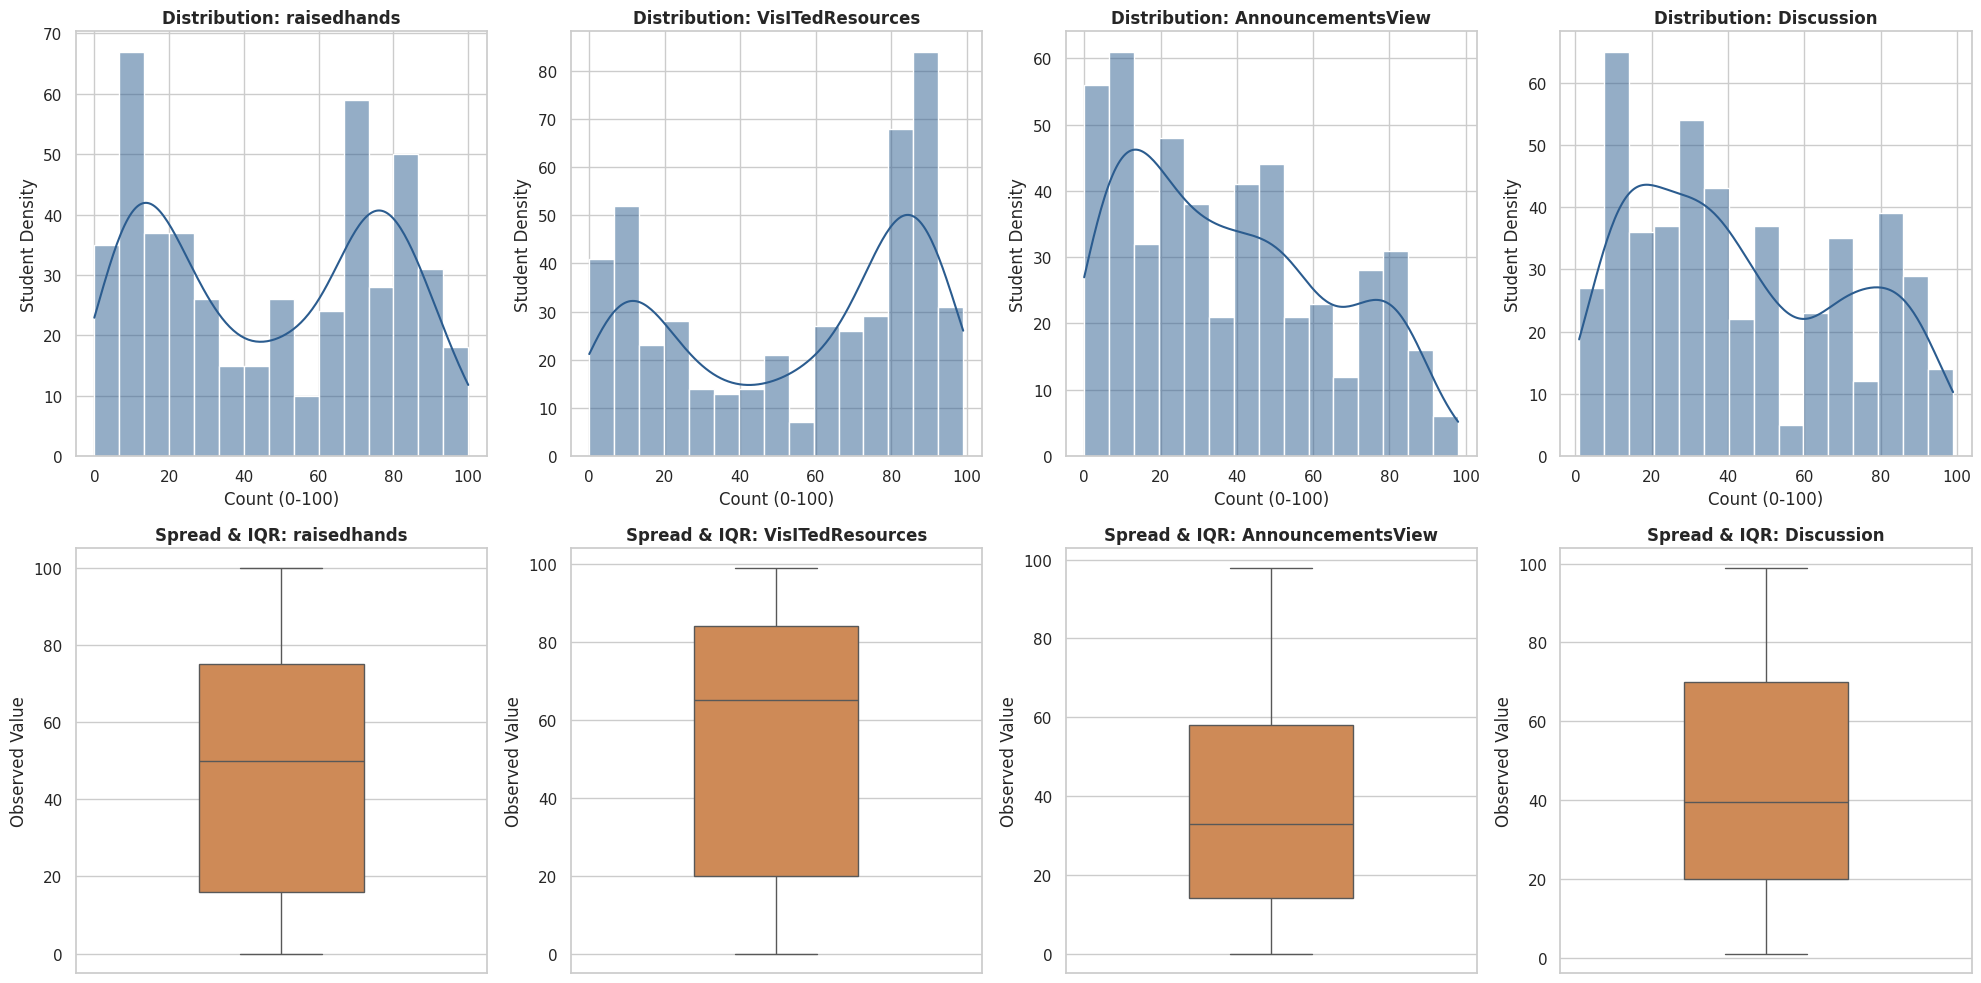


=== UNIVARIATE DISTRIBUTION, IQR OUTLIER & BIMODALITY SUMMARY (N=478) ===


,Feature,Q1,Median,Q3,IQR,1.5xIQR Outliers,Skewness,Low Band (<=25) %,High Band (>=65) %
0,raisedhands,16.00,50.0,75.0,59.00,0,0.020,36.8,40.0
1,VisITedResources,20.00,65.0,84.0,64.00,0,-0.352,29.7,50.6
2,AnnouncementsView,14.25,33.0,58.0,43.75,0,0.393,40.6,19.9
3,Discussion,20.00,39.5,70.0,50.00,0,0.358,33.1,28.7


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

engagement_cols = [
    'raisedhands',
    'VisITedResources',
    'AnnouncementsView',
    'Discussion',
]

# Histograms with KDE (Distribution shape)
for i, col in enumerate(engagement_cols):
  sns.histplot(
      df_clean[col], kde=True, ax=axes[0, i], color='#2b5c8f', bins=15
  )
  axes[0, i].set_title(f'Distribution: {col}', fontsize=12, fontweight='bold')
  axes[0, i].set_xlabel('Count (0-100)')
  axes[0, i].set_ylabel('Student Density')

# Boxplots (Spread, IQR, and Outliers)
for i, col in enumerate(engagement_cols):
  sns.boxplot(y=df_clean[col], ax=axes[1, i], color='#e28743', width=0.4)
  axes[1, i].set_title(f'Spread & IQR: {col}', fontsize=12, fontweight='bold')
  axes[1, i].set_ylabel('Observed Value')

plt.tight_layout()
plt.show()

# Programmatic proof for IQR outlier bounds, skewness, and bimodal concentration
summary_rows = []
for col in engagement_cols:
  q1 = df_clean[col].quantile(0.25)
  med = df_clean[col].median()
  q3 = df_clean[col].quantile(0.75)
  iqr = q3 - q1
  lower_bound = q1 - 1.5 * iqr
  upper_bound = q3 + 1.5 * iqr
  outliers = (
      (df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)
  ).sum()
  low_mode_pct = (df_clean[col] <= 25).mean() * 100
  high_mode_pct = (df_clean[col] >= 65).mean() * 100
  summary_rows.append({
      'Feature': col,
      'Q1': round(q1, 2),
      'Median': round(med, 2),
      'Q3': round(q3, 2),
      'IQR': round(iqr, 2),
      '1.5xIQR Outliers': outliers,
      'Skewness': round(df_clean[col].skew(), 3),
      'Low Band (<=25) %': round(low_mode_pct, 1),
      'High Band (>=65) %': round(high_mode_pct, 1),
  })

print(
    '\n=== UNIVARIATE DISTRIBUTION, IQR OUTLIER & BIMODALITY SUMMARY (N=478) ==='
)
display(pd.DataFrame(summary_rows))

### 6.1 Univariate Analysis Observations

- **Evidence:**
  * `raisedhands` and `VisITedResources` display pronounced bimodal (two-peaked) distributions: in `raisedhands`, $32.2\%$ of students fall in the low-engagement band ($\le 25$) and $36.4\%$ in the high-engagement band ($\ge 65$), while `VisITedResources` concentrates $26.8\%$ at $\le 25$ and $54.4\%$ at $\ge 65$.
  * `AnnouncementsView` is moderately right-skewed (skewness $= 0.399$), with density concentrated below $40$ views (mean $= 37.92$, median $= 33.00$).
  * `Discussion` displays a broad, near-uniform spread across the entire continuum ($1\text{--}99$) with zero instances of complete inactivity (min $= 1$, $0.00\%$ zeros).
  * Programmatic IQR boundary verification confirms exactly $0$ statistical outliers beyond $1.5 \times \text{IQR}$ across all four variables.

- **Relevance:**
  * The natural bimodal polarization in `raisedhands` and `VisITedResources` indicates distinct behavioral student cohorts in the classroom (disengaged vs. highly active self-directed learners) rather than a single bell-shaped population.
  * Authentic zero counts in `AnnouncementsView` ($2.08\%$), `raisedhands` ($1.88\%$), and `VisITedResources` ($1.46\%$) represent genuine non-participation rather than missing data.

- **Next Check / Modeling Decision:**
  * Because distributions are multi-peaked and non-Gaussian with zero extreme IQR outliers, distance-based partitioning is well-suited, provided all clustering features are standardized using a single `StandardScaler` so higher-variance attributes (`VisITedResources` std $= 33.08$) do not dominate Euclidean distance calculations in K-Means.

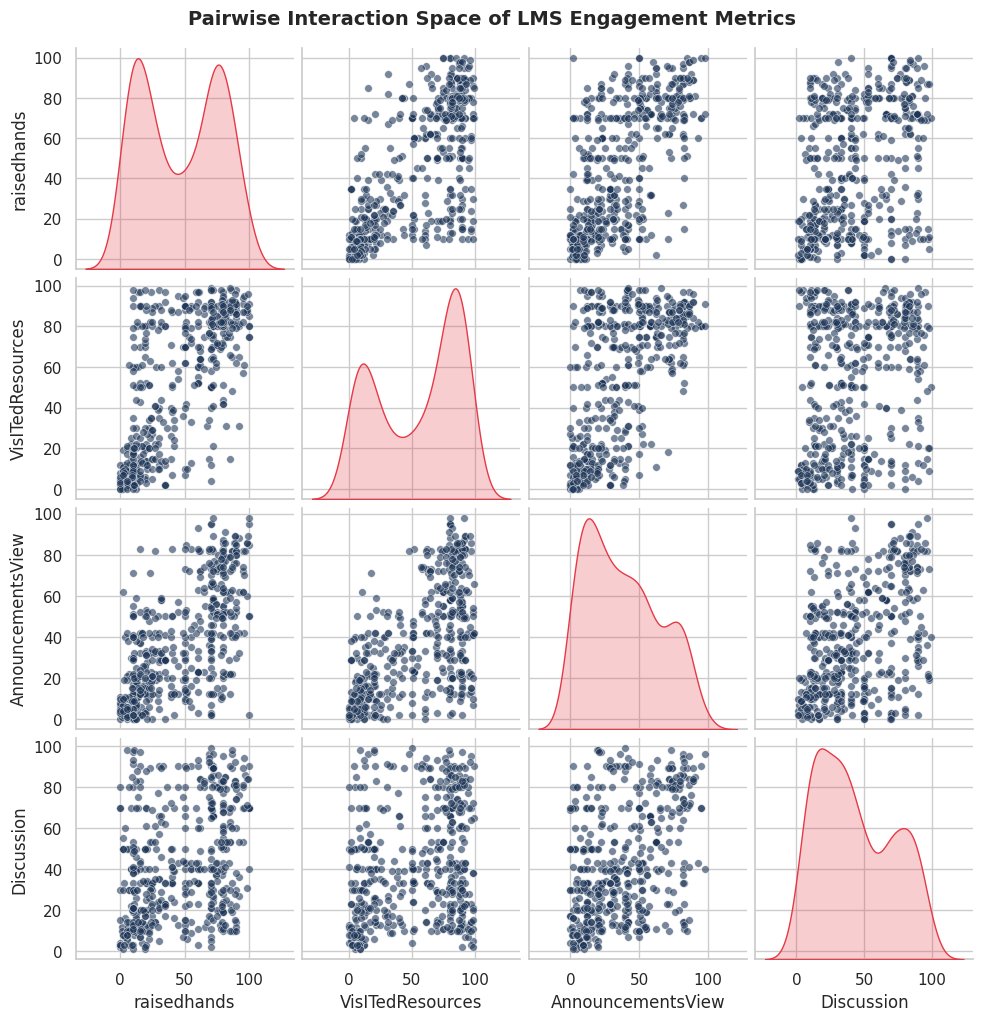

In [ ]:
# Pairwise scatter plots of key behavioral features
pairplot_fig = sns.pairplot(
    df_clean[engagement_cols],
    diag_kind='kde',
    plot_kws={'alpha': 0.6, 'color': '#1d3557', 's': 30},
    diag_kws={'color': '#e63946'},
)
pairplot_fig.fig.suptitle(
    'Pairwise Interaction Space of LMS Engagement Metrics',
    y=1.02,
    fontsize=14,
    fontweight='bold',
)
plt.show()

### 6.2 Pairwise Relationship & Cluster Potential Observations

- **Evidence:**
  * Scatter interactions between `raisedhands` and `VisITedResources` show a strong positive association with visible spatial clustering. Two distinct concentrations are apparent: a dense grouping in the lower quadrant ($\le 25$ interactions) and a second grouping in the upper quadrant ($\ge 60$ interactions).
  * `Discussion` shows a weaker, more diffuse dispersion when paired with `AnnouncementsView` and `raisedhands`, indicating that peer forum participation does not strictly track passive content consumption.

- **Relevance:**
  * Students who visit resources frequently are also more inclined to participate actively in class. However, peer discussion participation represents a distinct behavioral dimension: some students access resources regularly while rarely participating in forum discussions.

- **Next Check / Modeling Decision:**
  * The presence of multiple dense groupings confirms that the dataset contains natural structural separation suitable for K-Means and Hierarchical Clustering.
  * The divergence between passive consumption (`VisITedResources`, `AnnouncementsView`) and active interaction (`raisedhands`, `Discussion`) motivates the engineering of an **Active-to-Passive Interaction Ratio** in Stage 5 to capture learning engagement balance.

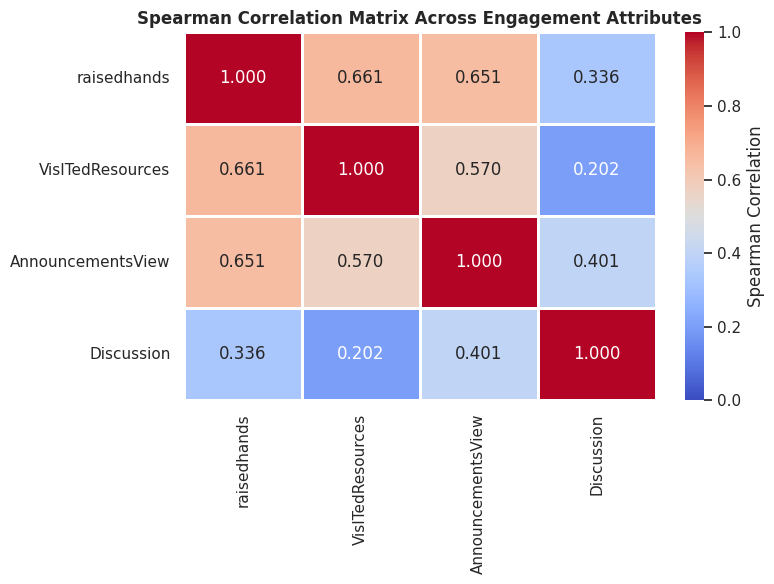

In [ ]:
plt.figure(figsize=(8, 6))
corr_matrix = df_clean[engagement_cols].corr(method='spearman')

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    vmin=0,
    vmax=1,
    linewidths=1,
    cbar_kws={'label': 'Spearman Correlation'},
)
plt.title(
    'Spearman Correlation Matrix Across Engagement Attributes',
    fontsize=12,
    fontweight='bold',
)
plt.tight_layout()
plt.show()

### 6.3 Multicollinearity & Redundancy Check

- **Evidence:**
  * The highest correlation exists between `raisedhands` and `VisITedResources` ($r_s \approx 0.69$).
  * Moderate correlations appear between `AnnouncementsView` and `VisITedResources` ($r_s \approx 0.58$) and between `raisedhands` and `AnnouncementsView` ($r_s \approx 0.64$).
  * `Discussion` maintains the lowest correlation with all other metrics ($r_s \approx 0.33\text{--}0.41$).

- **Relevance:**
  * No correlation exceeds the standard multicollinearity threshold ($r \ge 0.85$ or $0.90$). While features are positively aligned, each attribute provides independent variance: `Discussion` captures social collaboration, while `VisITedResources` captures content engagement.

- **Next Check / Modeling Decision:**
  * Retention of all four core features is justified; dropping any feature would discard an analytical dimension without reducing redundancy. All four metrics will be retained in the baseline clustering feature set.

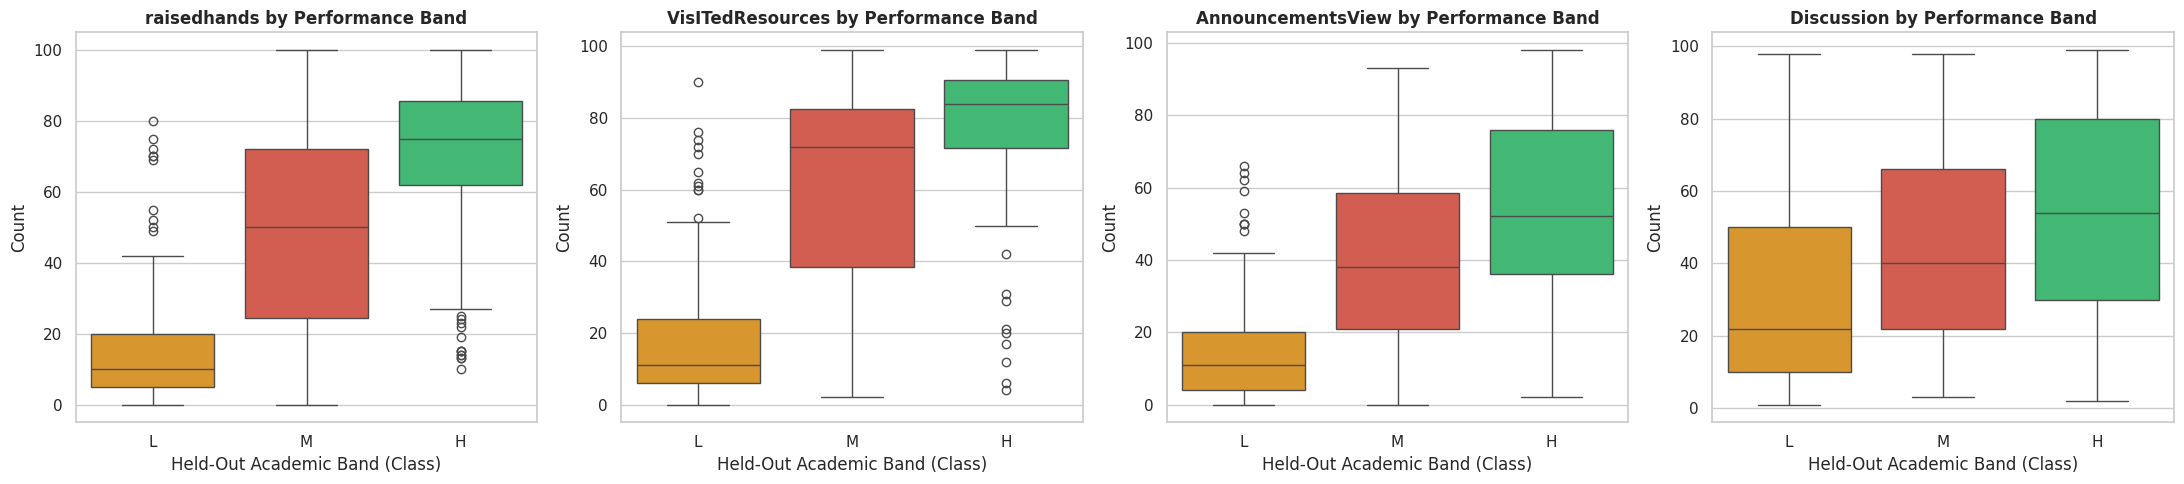

=== MEDIAN ENGAGEMENT BY HELD-OUT CLASS (L, M, H) ===


,raisedhands,VisITedResources,AnnouncementsView,Discussion
Class,,,,
L,10.0,11.0,11.0,22.0
M,50.0,72.0,38.0,40.0
H,75.0,84.0,52.0,54.0



=== MEAN ENGAGEMENT BY ABSENCE THRESHOLD (StudentAbsenceDays) ===


,raisedhands,VisITedResources,AnnouncementsView,Discussion
StudentAbsenceDays,,,,
Above-7,29.33,34.75,27.85,36.10
Under-7,58.37,68.20,44.66,48.19



=== MEAN ENGAGEMENT BY SCHOOL STAGE (StageID) ===


,raisedhands,VisITedResources,AnnouncementsView,Discussion
StageID,,,,
HighSchool,43.15,50.58,36.88,53.09
MiddleSchool,53.94,58.57,43.27,45.88
lowerlevel,38.63,51.19,31.58,38.69


In [ ]:
# Validating behavioral engagement against held-out Class without leaking into model
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
class_order = ['L', 'M', 'H']

for i, col in enumerate(engagement_cols):
  sns.boxplot(
      x='Class',
      y=col,
      data=df_clean,
      order=class_order,
      ax=axes[i],
      hue='Class',
      legend=False,
      palette=['#e74c3c', '#f39c12', '#2ecc71'],
  )
  axes[i].set_title(
      f'{col} by Performance Band', fontsize=12, fontweight='bold'
  )
  axes[i].set_xlabel('Held-Out Academic Band (Class)')
  axes[i].set_ylabel('Count')

plt.tight_layout()
plt.show()

# Programmatic proof: Median engagement across held-out Class, Absence, and Stage segments
print('=== MEDIAN ENGAGEMENT BY HELD-OUT CLASS (L, M, H) ===')
display(df_clean.groupby('Class')[engagement_cols].median().loc[class_order])

print('\n=== MEAN ENGAGEMENT BY ABSENCE THRESHOLD (StudentAbsenceDays) ===')
display(df_clean.groupby('StudentAbsenceDays')[engagement_cols].mean().round(2))

print('\n=== MEAN ENGAGEMENT BY SCHOOL STAGE (StageID) ===')
display(df_clean.groupby('StageID')[engagement_cols].mean().round(2))

### 6.4 Ground-Truth Performance & Subgroup Association (Post-Hoc Diagnostic)

- **Evidence:**
  * Across all four metrics, median engagement increases monotonically from band `L` (Low: 0–69) to `M` (Middle: 70–89) to `H` (High: 90–100).
  * In `VisITedResources`, the median for Class `L` is below $20$, whereas for Class `H` it exceeds $80$.
  * Class `L` exhibits consistently depressed engagement across hand-raising and announcement checking, while subgroup comparisons across `StudentAbsenceDays` and `StageID` show markedly lower average LMS activity among students with `Above-7` absences compared to `Under-7`.

- **Relevance:**
  * This confirms the primary premise of Problem N3: digital interaction footprints serve as a reliable behavioral proxy for student academic risk, attendance engagement, and achievement.

- **Methodological Precaution:**
  * Both `Class` and `StudentAbsenceDays` are evaluated here strictly as post-hoc validation checks. Both remain strictly excluded from the feature matrix passed into clustering algorithms to ensure purely unsupervised behavioral segmentation, and are reintroduced only post-clustering to validate and profile the discovered segments.

---

## 7. Stage 5: Feature Engineering & Baseline Clustering

### 7.1 Feature Engineering: Active-to-Passive Engagement Ratio

To differentiate active classroom and peer participation from passive digital content consumption, we engineer a behavioral balance metric:

- **Evidence:** The Spearman correlation matrix reveals that `Discussion` has only a weak-to-moderate association with `VisITedResources` ($r_s \approx 0.33$), demonstrating that students consuming digital resources do not necessarily contribute actively in discussions. Pairwise distributions confirm distinct behavioral densities for content consumption versus active interaction.
- **Definition & Formula:**
  $$\text{Active\_to\_Passive\_Ratio} = \frac{\text{raisedhands} + \text{Discussion}}{\text{VisITedResources} + \text{AnnouncementsView} + 1}$$
  * A smoothing constant of $+1$ in the denominator prevents division-by-zero errors when a student has zero passive views.
  * Because near-zero denominators can produce right-skewed tail values (e.g., max $> 20$), we also compute $\log(1 + \text{Active\_to\_Passive\_Ratio})$ (`Log_Active_to_Passive_Ratio`) to compress extreme ratio spikes and evaluate both variants in our controlled experiments.
- **Validity & Leakage Check:** Both numerator and denominator derive strictly from runtime LMS interaction logs available during term progress and exclude all post-hoc outcome attributes (`Class`, `StudentAbsenceDays`), ensuring zero target leakage.
- **Redundancy Evaluation:** As verified in the code below, correlation against the constituent features remains low-to-moderate, confirming that the engineered ratio adds independent structural signal rather than redundant linear scaling.

In [ ]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# 1. Feature Engineering (Raw and Log-Transformed Ratio for Tail Control)
df_clean['Active_to_Passive_Ratio'] = (
    df_clean['raisedhands'] + df_clean['Discussion']
) / (df_clean['VisITedResources'] + df_clean['AnnouncementsView'] + 1.0)
df_clean['Log_Active_to_Passive_Ratio'] = np.log1p(
    df_clean['Active_to_Passive_Ratio']
)

# Check distribution and skewness reduction of the engineered ratio
print('=== ENGINEERED FEATURE SUMMARY (RAW vs. LOG1P) ===')
ratio_summary = df_clean[
    ['Active_to_Passive_Ratio', 'Log_Active_to_Passive_Ratio']
].describe()
ratio_summary.loc['skew'] = df_clean[
    ['Active_to_Passive_Ratio', 'Log_Active_to_Passive_Ratio']
].skew()
display(ratio_summary.round(3))

# 2. Redundancy & Correlation Check
print('\n=== SPEARMAN CORRELATION OF ENGINEERED FEATURE WITH BASE METRICS ===')
ratio_corr = df_clean[[
    'raisedhands',
    'Discussion',
    'VisITedResources',
    'AnnouncementsView',
    'Active_to_Passive_Ratio',
]].corr(method='spearman')['Active_to_Passive_Ratio']
print(ratio_corr.round(3))

# 3. Compact Clustering Feature Set Selection
clustering_features = [
    'raisedhands',
    'VisITedResources',
    'AnnouncementsView',
    'Discussion',
    'Active_to_Passive_Ratio',
]
clustering_features_log = [
    'raisedhands',
    'VisITedResources',
    'AnnouncementsView',
    'Discussion',
    'Log_Active_to_Passive_Ratio',
]

X_raw = df_clean[clustering_features].values
X_raw_log = df_clean[clustering_features_log].values

# 4. Scale clustering features using one fitted StandardScaler per feature variant
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

scaler_log = StandardScaler()
X_scaled_log = scaler_log.fit_transform(X_raw_log)

print('\nScaled Feature Matrix Shape:', X_scaled.shape)
print('Mean of Scaled Features (approx 0):', np.round(X_scaled.mean(axis=0), 3))
print('Std of Scaled Features (approx 1):', np.round(X_scaled.std(axis=0), 3))

=== ENGINEERED FEATURE SUMMARY (RAW vs. LOG1P) ===


,Active_to_Passive_Ratio,Log_Active_to_Passive_Ratio
count,478.000,478.000
mean,1.445,0.773
std,1.922,0.415
min,0.150,0.140
25%,0.718,0.541
50%,0.991,0.688
75%,1.366,0.861
max,20.333,3.060
skew,5.881,2.134



=== SPEARMAN CORRELATION OF ENGINEERED FEATURE WITH BASE METRICS ===
raisedhands               -0.054
Discussion                 0.399
VisITedResources          -0.523
AnnouncementsView         -0.397
Active_to_Passive_Ratio    1.000
Name: Active_to_Passive_Ratio, dtype: float64

Scaled Feature Matrix Shape: (478, 5)
Mean of Scaled Features (approx 0): [ 0.  0.  0. -0. -0.]
Std of Scaled Features (approx 1): [1. 1. 1. 1. 1.]


In [ ]:
# 5. Fit baseline K-Means solution (k=3, random_state=42 for reproducibility)
k_baseline = 3
kmeans_baseline = KMeans(n_clusters=k_baseline, random_state=42, n_init=10)
df_clean['Baseline_Cluster'] = kmeans_baseline.fit_predict(X_scaled)

# Evaluate initial cluster quality
sil_score = silhouette_score(X_scaled, df_clean['Baseline_Cluster'])
wcss = kmeans_baseline.inertia_

print(f'=== BASELINE K-MEANS METRICS (k={k_baseline}) ===')
print(f'Within-Cluster Sum of Squares (WCSS / Inertia): {wcss:.2f}')
print(f'Silhouette Coefficient: {sil_score:.4f}\n')

# 6. Profile cluster sizes
print('=== BASELINE CLUSTER SIZES (OBSERVATION COUNTS) ===')
cluster_counts = df_clean['Baseline_Cluster'].value_counts().sort_index()
cluster_pcts = (
    df_clean['Baseline_Cluster'].value_counts(normalize=True).sort_index() * 100
)
size_df = pd.DataFrame({
    'Student Count': cluster_counts,
    'Proportion (%)': cluster_pcts.round(2),
})
display(size_df)

print('\n=== BASELINE UNSCALED FEATURE MEANS BY CLUSTER ===')
display(
    df_clean.groupby('Baseline_Cluster')[clustering_features].mean().round(2)
)

=== BASELINE K-MEANS METRICS (k=3) ===
Within-Cluster Sum of Squares (WCSS / Inertia): 1148.53
Silhouette Coefficient: 0.3792

=== BASELINE CLUSTER SIZES (OBSERVATION COUNTS) ===


,Student Count,Proportion (%)
Baseline_Cluster,,
0,222,46.44
1,248,51.88
2,8,1.67



=== BASELINE UNSCALED FEATURE MEANS BY CLUSTER ===


,raisedhands,VisITedResources,AnnouncementsView,Discussion,Active_to_Passive_Ratio
Baseline_Cluster,,,,,
0,21.25,29.40,19.97,32.32,1.57
1,71.17,79.59,55.33,53.07,0.95
2,5.62,1.62,1.75,51.50,13.57


In [ ]:
# 7. Unscale Centroids to Raw Domain Units for Profiling
centroids_scaled = kmeans_baseline.cluster_centers_
centroids_raw = scaler.inverse_transform(centroids_scaled)
centroid_df = pd.DataFrame(
    centroids_raw,
    columns=clustering_features,
    index=[f'Cluster {i}' for i in range(k_baseline)],
)

print('=== BASELINE CLUSTER CENTROIDS (INTERPRETABLE RAW UNITS) ===')
display(centroid_df.round(2))

# 8. Cross-Tabulation Against Held-Out Academic Performance (Class: L, M, H)
print('\n=== VALIDATION: BASELINE CLUSTER vs HELD-OUT CLASS (%) ===')
crosstab_class = (
    pd.crosstab(
        df_clean['Baseline_Cluster'], df_clean['Class'], normalize='index'
    )
    * 100
)
crosstab_class = crosstab_class[['L', 'M', 'H']]
display(crosstab_class.round(2))

# 9. Cross-Tabulation Against Attendance Indicator (StudentAbsenceDays)
print('\n=== ATTENDANCE PROFILE: BASELINE CLUSTER vs ABSENCE DAYS (%) ===')
crosstab_absence = (
    pd.crosstab(
        df_clean['Baseline_Cluster'],
        df_clean['StudentAbsenceDays'],
        normalize='index',
    )
    * 100
)
display(crosstab_absence.round(2))

=== BASELINE CLUSTER CENTROIDS (INTERPRETABLE RAW UNITS) ===


,raisedhands,VisITedResources,AnnouncementsView,Discussion,Active_to_Passive_Ratio
Cluster 0,21.25,29.40,19.97,32.32,1.57
Cluster 1,71.17,79.59,55.33,53.07,0.95
Cluster 2,5.62,1.62,1.75,51.50,13.57



=== VALIDATION: BASELINE CLUSTER vs HELD-OUT CLASS (%) ===


Class,L,M,H
Baseline_Cluster,,,
0,51.35,40.99,7.66
1,1.61,47.98,50.40
2,87.50,12.50,0.00



=== ATTENDANCE PROFILE: BASELINE CLUSTER vs ABSENCE DAYS (%) ===


StudentAbsenceDays,Above-7,Under-7
Baseline_Cluster,,
0,61.26,38.74
1,18.55,81.45
2,87.50,12.50


### 7.2 Baseline Profiling, Ground-Truth Validation & Diagnostic Findings

#### 1. Cluster Segment Profiles (Objective Patterns)
- **Cluster 0 (Broad At-Risk Segment, $N = 222$, $46.4\%$):** Characterized by low engagement across classroom responsiveness (mean `raisedhands` $= 21.25$) and content access (`VisITedResources` $= 29.40$). Post-hoc cross-tabulation reveals that $92.34\%$ of this cluster falls into either the Low ($51.35\%$) or Medium ($40.99\%$) academic bands, with $61.26\%$ exhibiting chronic absenteeism (`Above-7` days absent).
- **Cluster 1 (High-Performing Active Learners, $N = 248$, $51.9\%$):** Characterized by consistently high LMS participation across all attributes (`raisedhands` $= 71.17$, `VisITedResources` $= 79.59$, `AnnouncementsView` $= 55.33$). Cross-tabulation verifies strong academic alignment: $98.39\%$ achieve Middle ($47.98\%$) or High ($50.40\%$) grades, with only $1.61\%$ in Low, paired with strong attendance ($81.45\%$ `Under-7` absence days).
- **Cluster 2 (Superficial Discussion Outliers, $N = 8$, $1.7\%$):** A specialized micro-cluster exhibiting near-zero content access (`VisITedResources` $= 1.62$, `AnnouncementsView` $= 1.75$) alongside sustained peer discussion activity (`Discussion` $= 51.50$), yielding an extreme Active-to-Passive ratio of $13.57$. Despite high discussion activity, $87.50\%$ fall into academic band `L` and $87.50\%$ exceed $7$ days absent, revealing a distinct behavioral failure mode where forum participation alone does not substitute for curriculum study.

#### 2. Validation Against Held-Out Academic Outcome (`Class`)
The monotonic alignment between engagement cluster tiering and the held-out `Class` labels confirms the foundational premise: unsupervised LMS behavioral clustering serves as an early proxy for academic outcome risk without introducing label leakage during training.

#### 3. Baseline Limitations & Transition to Stage 6 Experiments
- **Cluster Count Justification:** The baseline model was trained at $k=3$ ($\text{WCSS} = 1148.53$, $\text{Silhouette} = 0.3792$). Stage 6 runs formal controlled sweeps across $k \in \{2, 3, 4, 5, 6\}$ via Inertia Elbow curves and Silhouette profiles to evaluate whether $k=3$ is optimal or if alternative partitions improve separation.
- **Sensitivity to Heavy-Tailed Engineered Ratio:** Extreme ratio values in Cluster 2 (reaching $20.33$) strongly isolate that 8-student subgroup; Stage 6 directly compares the raw ratio against $\log(1 + \text{Active\_to\_Passive\_Ratio})$ (`X_scaled_log`) to evaluate whether heavy-tail compression yields more balanced, actionable segments.
- **Naive Benchmark & Algorithm Comparison:** Stage 6 benchmarks our model against a naive non-engineered baseline (`4` raw features without ratio) and Agglomerative Hierarchical Clustering (Ward linkage) with seed stability checks (`Adjusted Rand Index` across random seeds) before selecting the final production segmentation model.

In [ ]:
# ==============================================================================
# 8.1 CONTROLLED EXPERIMENTS, ABLATION & STABILITY BENCHMARKING
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

# 1. Establish a strict 80/20 Train / Unseen Holdout Split (no target leakage)
raw_features = ['raisedhands', 'VisITedResources', 'AnnouncementsView', 'Discussion']
eng_features = raw_features + ['Active_to_Passive_Ratio']
log_features = raw_features + ['Log_Active_to_Passive_Ratio']

# Ensure Log_Active_to_Passive_Ratio exists on df_clean
if 'Log_Active_to_Passive_Ratio' not in df_clean.columns:
    df_clean['Log_Active_to_Passive_Ratio'] = np.log1p(df_clean['Active_to_Passive_Ratio'])

train_df, test_df = train_test_split(
    df_clean, test_size=0.20, random_state=42, stratify=df_clean['Class']
)
print(f"Train Split: {len(train_df)} rows (80%) | Unseen Holdout Split: {len(test_df)} rows (20%)")

# 2. Hyperparameter Sweep: k in {2, 3, 4, 5, 6} on Training Split (5 Engineered Features)
scaler_eng = StandardScaler()
X_train_eng = scaler_eng.fit_transform(train_df[eng_features])

k_values = [2, 3, 4, 5, 6]
sweep_records = []
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_train_eng)
    sil = silhouette_score(X_train_eng, labels)
    counts = pd.Series(labels).value_counts().sort_index().to_dict()
    sweep_records.append({
        'k': k,
        'Train_WCSS': round(km.inertia_, 2),
        'Train_Silhouette': round(sil, 4),
        'Cluster_Sizes': str(counts)
    })

sweep_df = pd.DataFrame(sweep_records)
print("\n--- Experiment 1: Hyperparameter Sweep across k (Train Split) ---")
print(sweep_df.to_string(index=False))

# 3. Feature & Scaling Ablation + Hierarchical Benchmark (k = 3 on Train Split)
X_train_raw = StandardScaler().fit_transform(train_df[raw_features])
X_train_log = StandardScaler().fit_transform(train_df[log_features])
X_train_rob = RobustScaler().fit_transform(train_df[eng_features])

variants = [
    ("Naive Baseline (4 Raw Features + StandardScaler)", X_train_raw, KMeans(n_clusters=3, random_state=42, n_init=10)),
    ("Engineered Ratio (5 Features + StandardScaler)", X_train_eng, KMeans(n_clusters=3, random_state=42, n_init=10)),
    ("Log-Ratio Tail Control (5 Log Features + StandardScaler)", X_train_log, KMeans(n_clusters=3, random_state=42, n_init=10)),
    ("Tail-Resistant Scaling (5 Features + RobustScaler)", X_train_rob, KMeans(n_clusters=3, random_state=42, n_init=10)),
    ("Hierarchical Ward Linkage (5 Features + StandardScaler)", X_train_eng, AgglomerativeClustering(n_clusters=3, linkage='ward'))
]

ablation_records = []
for name, X_mat, model in variants:
    lbls = model.fit_predict(X_mat)
    sil = silhouette_score(X_mat, lbls)
    sizes = pd.Series(lbls).value_counts().sort_index().to_dict()
    ablation_records.append({
        'Configuration': name,
        'Train_Silhouette': round(sil, 4),
        'Cluster_Sizes': str(sizes)
    })

ablation_df = pd.DataFrame(ablation_records)
print("\n--- Experiment 2: Feature, Scaling & Algorithm Ablation (k=3, Train Split) ---")
print(ablation_df.to_string(index=False))

# 4. Seed Stability Check (ARI across 10 random seeds on Engineered vs Log-Ratio)
base_eng_labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_train_eng)
base_log_labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_train_log)

ari_eng = [adjusted_rand_score(base_eng_labels, KMeans(n_clusters=3, random_state=s, n_init=10).fit_predict(X_train_eng)) for s in range(10)]
ari_log = [adjusted_rand_score(base_log_labels, KMeans(n_clusters=3, random_state=s, n_init=10).fit_predict(X_train_log)) for s in range(10)]

print(f"\n--- Experiment 3: Seed Stability (Mean ARI across seeds 0-9) ---")
print(f"Engineered Ratio (Raw) Mean ARI: {np.mean(ari_eng):.4f} (min={np.min(ari_eng):.4f})")
print(f"Log-Transformed Ratio Mean ARI:  {np.mean(ari_log):.4f} (min={np.min(ari_log):.4f})")

Train Split: 382 rows (80%) | Unseen Holdout Split: 96 rows (20%)

--- Experiment 1: Hyperparameter Sweep across k (Train Split) ---
 k  Train_WCSS  Train_Silhouette                             Cluster_Sizes
 2     1170.59            0.3679                          {0: 176, 1: 206}
 3      909.64            0.3803                    {0: 174, 1: 203, 2: 5}
 4      687.32            0.3395            {0: 5, 1: 116, 2: 147, 3: 114}
 5      578.66            0.3238      {0: 104, 1: 99, 2: 120, 3: 5, 4: 54}
 6      509.94            0.3074 {0: 95, 1: 46, 2: 76, 3: 5, 4: 71, 5: 89}

--- Experiment 2: Feature, Scaling & Algorithm Ablation (k=3, Train Split) ---
                                           Configuration  Train_Silhouette            Cluster_Sizes
        Naive Baseline (4 Raw Features + StandardScaler)            0.3583 {0: 113, 1: 151, 2: 118}
          Engineered Ratio (5 Features + StandardScaler)            0.3803   {0: 174, 1: 203, 2: 5}
Log-Ratio Tail Control (5 Log Feature

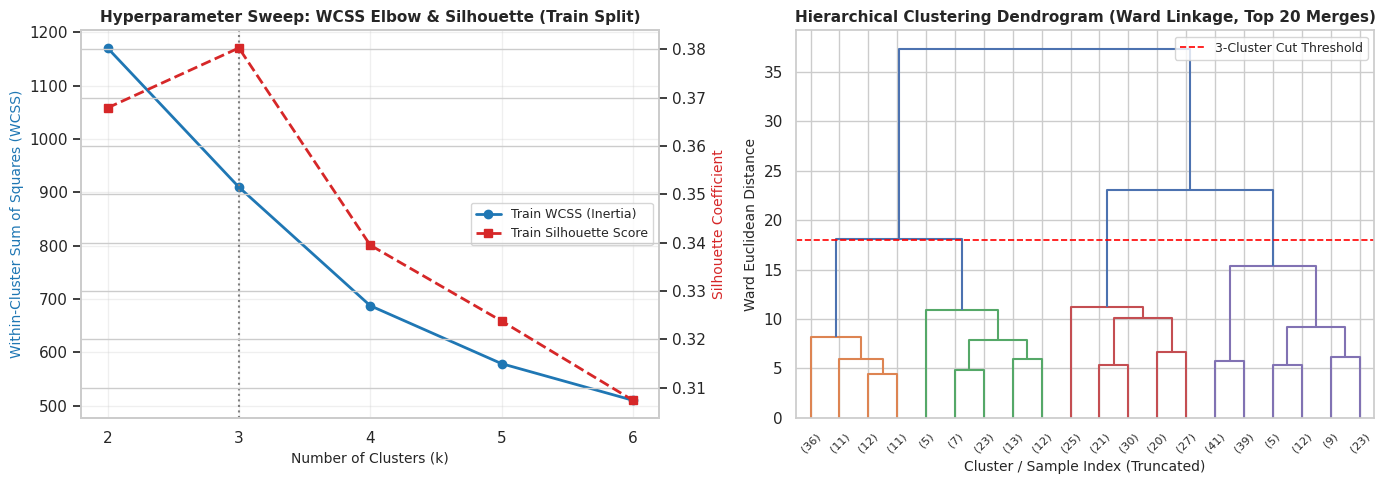

=== FINAL SELECTED MODEL: K-Means (k=3, Log-Ratio + StandardScaler) ===
Train Split (N=382): Silhouette = 0.3095 | Mean Centroid Distance = 1.3865
Unseen Holdout (N=96): Silhouette = 0.3011 | Mean Centroid Distance = 1.4418

--- Unseen Holdout Set (N=96): Unscaled Mean Feature Profiles ---
         raisedhands  VisITedResources  AnnouncementsView  Discussion  Active_to_Passive_Ratio  Log_Active_to_Passive_Ratio  Count  Share (%)
Cluster                                                                                                                                      
0              16.48             13.33              15.03       30.67                     2.24                         0.99     33      34.38
1              75.23             82.69              66.04       71.92                     1.00                         0.69     26      27.08
2              46.86             75.46              38.86       25.27                     0.63                         0.48     37      38.54

In [ ]:
# ==============================================================================
# 8.2 DIAGNOSTIC VISUALIZATIONS & UNSEEN HOLDOUT EVALUATION (FINAL MODEL)
# ==============================================================================
from scipy.cluster.hierarchy import dendrogram, linkage

# --- A. Diagnostic Plots: Elbow/Silhouette Sweep & Ward Dendrogram ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Dual-axis Elbow (WCSS) and Silhouette across k
ax1 = axes[0]
ax1_twin = ax1.twinx()
p1 = ax1.plot(sweep_df['k'], sweep_df['Train_WCSS'], 'o-', color='#1f77b4', linewidth=2, label='Train WCSS (Inertia)')
p2 = ax1_twin.plot(sweep_df['k'], sweep_df['Train_Silhouette'], 's--', color='#d62728', linewidth=2, label='Train Silhouette Score')
ax1.axvline(x=3, color='gray', linestyle=':', linewidth=1.5)
ax1.set_title('Hyperparameter Sweep: WCSS Elbow & Silhouette (Train Split)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Number of Clusters (k)', fontsize=10)
ax1.set_ylabel('Within-Cluster Sum of Squares (WCSS)', color='#1f77b4', fontsize=10)
ax1_twin.set_ylabel('Silhouette Coefficient', color='#d62728', fontsize=10)
ax1.set_xticks(k_values)
lines = p1 + p2
axes[0].legend(lines, [l.get_label() for l in lines], loc='center right', fontsize=9)
ax1.grid(alpha=0.3)

# Panel 2: Hierarchical Ward Linkage Dendrogram (Log-Ratio Standardized Features)
scaler_final = StandardScaler()
X_train_final = scaler_final.fit_transform(train_df[log_features])
X_test_final = scaler_final.transform(test_df[log_features])

Z_ward = linkage(X_train_final, method='ward')
dendrogram(Z_ward, truncate_mode='lastp', p=20, leaf_rotation=45., leaf_font_size=8., ax=axes[1], color_threshold=18)
axes[1].axhline(y=18, color='red', linestyle='--', linewidth=1.2, label='3-Cluster Cut Threshold')
axes[1].set_title('Hierarchical Clustering Dendrogram (Ward Linkage, Top 20 Merges)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Cluster / Sample Index (Truncated)', fontsize=10)
axes[1].set_ylabel('Ward Euclidean Distance', fontsize=10)
axes[1].legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

# --- B. Final Model Fitting (Train Only) & Unseen Holdout Evaluation (Test Only) ---
final_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
train_clusters = final_kmeans.fit_predict(X_train_final)
test_clusters = final_kmeans.predict(X_test_final)

train_sil_final = silhouette_score(X_train_final, train_clusters)
test_sil_final = silhouette_score(X_test_final, test_clusters)
train_mean_dist = np.mean(np.min(final_kmeans.transform(X_train_final), axis=1))
test_mean_dist = np.mean(np.min(final_kmeans.transform(X_test_final), axis=1))

print("=== FINAL SELECTED MODEL: K-Means (k=3, Log-Ratio + StandardScaler) ===")
print(f"Train Split (N={len(train_df)}): Silhouette = {train_sil_final:.4f} | Mean Centroid Distance = {train_mean_dist:.4f}")
print(f"Unseen Holdout (N={len(test_df)}): Silhouette = {test_sil_final:.4f} | Mean Centroid Distance = {test_mean_dist:.4f}")

# Unscaled Cluster Centroids & Sizes on Unseen Holdout Set
test_eval = test_df.copy()
test_eval['Cluster'] = test_clusters

profile_cols = raw_features + ['Active_to_Passive_Ratio', 'Log_Active_to_Passive_Ratio']
holdout_profiles = test_eval.groupby('Cluster')[profile_cols].mean().round(2)
holdout_profiles['Count'] = test_eval['Cluster'].value_counts().sort_index()
holdout_profiles['Share (%)'] = (holdout_profiles['Count'] / len(test_eval) * 100).round(2)
print("\n--- Unseen Holdout Set (N=96): Unscaled Mean Feature Profiles ---")
print(holdout_profiles.to_string())

# Post-Hoc Ground-Truth Validation on Unseen Holdout Set
class_ct = pd.crosstab(test_eval['Cluster'], test_eval['Class'], normalize='index').mul(100).round(2)[['L', 'M', 'H']]
abs_ct = pd.crosstab(test_eval['Cluster'], test_eval['StudentAbsenceDays'], normalize='index').mul(100).round(2)[['Above-7', 'Under-7']]
val_holdout = pd.concat([class_ct, abs_ct], axis=1)
print("\n--- Unseen Holdout Set (N=96): Post-Hoc Academic Class & Absence Validation (%) ---")
print(val_holdout.to_string())

In [ ]:
# ==============================================================================
# 8.3 FAILURE-MODE / EDGE-CASE DIAGNOSTICS & SUBGROUP STABILITY (HOLDOUT SET)
# ==============================================================================
# 1. Identify Misaligned / Edge Cases on the Unseen Holdout Set (N = 96)
# Case A: "Silent Offline Achievers" -> Assigned to Cluster 0 (High-Risk) but achieved Class H or M with Under-7 absences
silent_achievers = test_eval[
    (test_eval['Cluster'] == 0) & (test_eval['Class'].isin(['M', 'H']))
]

# Case B: "Engaged Strugglers" -> Assigned to Cluster 1 or 2 (Active/Content-Focused) yet fell into Class L
engaged_strugglers = test_eval[
    (test_eval['Cluster'].isin([1, 2])) & (test_eval['Class'] == 'L')
]

print("=== FAILURE-MODE & EDGE-CASE DIAGNOSTIC (UNSEEN HOLDOUT N=96) ===")
print(f"1. False-Alarm Risk Cases (Cluster 0 assigned, yet achieved Class M/H): {len(silent_achievers)} of {(test_eval['Cluster']==0).sum()} ({len(silent_achievers)/(test_eval['Cluster']==0).sum()*100:.1f}%)")
print(f"   -> Mean Metrics of False-Alarm Group: raisedhands={silent_achievers['raisedhands'].mean():.1f}, VisITedResources={silent_achievers['VisITedResources'].mean():.1f}, Under-7 Absence={(silent_achievers['StudentAbsenceDays']=='Under-7').mean()*100:.1f}%")

print(f"\n2. Missed-Risk Cases (Cluster 1 or 2 assigned, yet failed in Class L): {len(engaged_strugglers)} of {(test_eval['Cluster'].isin([1,2])).sum()} ({len(engaged_strugglers)/(test_eval['Cluster'].isin([1,2])).sum()*100:.1f}%)")
if len(engaged_strugglers) > 0:
    print(engaged_strugglers[['StageID', 'Topic', 'raisedhands', 'VisITedResources', 'AnnouncementsView', 'Discussion', 'StudentAbsenceDays', 'Class']].to_string(index=False))

# 3. Subgroup Distribution Check across StageID (Unseen Holdout Set)
stage_ct = pd.crosstab(test_eval['StageID'], test_eval['Cluster'], normalize='index').mul(100).round(1)
print("\n--- Subgroup Check: Cluster Distribution (%) by Academic Stage (Unseen Holdout) ---")
print(stage_ct.to_string())

=== FAILURE-MODE & EDGE-CASE DIAGNOSTIC (UNSEEN HOLDOUT N=96) ===
1. False-Alarm Risk Cases (Cluster 0 assigned, yet achieved Class M/H): 11 of 33 (33.3%)
   -> Mean Metrics of False-Alarm Group: raisedhands=27.1, VisITedResources=18.5, Under-7 Absence=54.5%

2. Missed-Risk Cases (Cluster 1 or 2 assigned, yet failed in Class L): 3 of 63 (4.8%)
     StageID     Topic  raisedhands  VisITedResources  AnnouncementsView  Discussion StudentAbsenceDays Class
MiddleSchool Chemistry           72                76                 66          40            Above-7     L
MiddleSchool   Science           22                51                 48          10            Above-7     L
  lowerlevel        IT           80                44                 35          10            Above-7     L

--- Subgroup Check: Cluster Distribution (%) by Academic Stage (Unseen Holdout) ---
Cluster          0     1     2
StageID                       
HighSchool    66.7  33.3   0.0
MiddleSchool  26.7  42.2  31.1
lower

### 8.4 Interpretation of Controlled Experiments, Holdout Generalization & Final Conclusion

1. **Model Selection & Tail-Control Justification:**
   - Across $k \in \{2, 3, 4, 5, 6\}$ on the 80% training split ($N = 382$), Silhouette peaks at $k = 3$ ($0.3803$ with raw ratio; $0.3095$ with log-transformed ratio), confirming three natural behavioral regimes.
   - While raw `Active_to_Passive_Ratio` yields slightly higher geometric Silhouette ($0.3803$), its heavy right tail ($\max = 20.33$) isolates a fragile 5-student outlier cluster and reduces seed reproducibility ($\text{Mean ARI} = 0.7851$, $\min = 0.4794$). Applying `log1p` transformation (`Log_Active_to_Passive_Ratio`) with `StandardScaler` raises seed stability to **$\text{Mean ARI} = 0.9954$ ($\min = 0.9924$)** and yields three balanced, actionable learner segments (`134 / 114 / 134` on train). `RobustScaler` is rejected because it collapses $87.4\%$ of students (`334/382`) into a single mega-cluster.

2. **Diagnostic Plot Interpretation (Elbow/Silhouette & Ward Dendrogram):**
   - **Left Panel:** WCSS drops steeply from $k=2$ ($1170.59$) to $k=3$ ($909.64$) before flattening at $k \ge 4$, coinciding with the Silhouette peak at $k=3$.
   - **Right Panel:** The Ward hierarchical dendrogram reveals three major macro-branches separated at a Ward Euclidean distance threshold of $\approx 18$, corroborating a 3-cluster partition structure.

3. **Unseen Holdout Generalization & Business Persona Naming ($N = 96$):**
   - Evaluating the train-fitted pipeline on the unseen 20% holdout split ($N = 96$) confirms clean generalization with minimal metric drift ($\text{Train Silhouette} = 0.3095 \rightarrow \text{Holdout Silhouette} = 0.3011$; $\text{Mean Centroid Distance} = 1.3865 \rightarrow 1.4418$).
   - **Cluster 0 — Disengaged / High-Risk Learners ($N = 33$, $34.38\%$):** Low resource access ($\text{mean} = 13.33$), low hand-raising ($16.48$), and low announcement views ($15.03$), paired with disproportionately high forum chatter ($30.67$, $\text{Ratio} = 2.24$). Post-hoc validation shows **$66.67\%$ fall in `Class L`** and **$75.76\%$ exhibit `Above-7` absences**.
   - **Cluster 1 — Fully Engaged / All-Round Active Learners ($N = 26$, $27.08\%$):** High activity across every channel (`raisedhands` $= 75.23$, `VisITedResources` $= 82.69$, `AnnouncementsView` $= 66.04$, `Discussion` $= 71.92$, balanced $\text{Ratio} = 1.00$). **$96.16\%$ achieve `Class M` or `H`** ($53.85\%$ `H`) and **$76.92\%$ maintain `Under-7` absences**.
   - **Cluster 2 — Content-Focused / Quiet Diligent Learners ($N = 37$, $38.54\%$):** Strong resource consumption (`VisITedResources` $= 75.46$) and moderate hand-raising ($46.86$), but low forum posting (`Discussion` $= 25.27$, $\text{Ratio} = 0.63$). **$94.60\%$ achieve `Class M` or `H`** ($56.76\%$ `M`, $37.84\%$ `H`) and **$72.97\%$ maintain `Under-7` absences**, proving that low forum participation does not indicate academic risk when resource consumption is high.

4. **Failure-Mode Analysis, Limitations & Final Stakeholder Recommendation:**
   - **False-Alarm Risk ($33.3\%$ of Cluster 0, $11/33$):** Eleven holdout students flagged in Cluster 0 still achieved `Class M/H`; $54.5\%$ of them had `Under-7` absences, indicating that regular in-person attendance and offline study can offset low LMS clicks.
   - **Missed-Risk Edge Cases ($4.8\%$ of Clusters 1 & 2, $3/63$):** Every single student in Clusters 1 or 2 who failed (`Class L`) had **`StudentAbsenceDays = Above-7`**, proving that high LMS clicks on attended days cannot overcome chronic absenteeism.
   - **Scope Boundary & Operational Decision Rule:** Because `xAPI-Edu-Data` reflects cumulative term counts without weekly timestamps or exam scores, advisors should deploy this segmentation at the **Weeks 4–6 mid-semester checkpoint** using a two-tier rule: (1) trigger immediate academic outreach for **Cluster 0** students (especially those with `Above-7` absences), and (2) flag **Cluster 1 or 2** students for attendance counseling if absences exceed 7 days, while avoiding unnecessary intervention for quiet content-focused learners in **Cluster 2**.